# Placing a star on the Lyot bar

To run this notebook, you will need the `pysiaf` library. Documentation can be found here: `https://pysiaf.readthedocs.io/en/latest/`. To install, simply run `pip install pysiaf` in the appropriate python environment.

In [13]:
import pysiaf
import matplotlib as mpl
from matplotlib import pyplot as plt
import numpy as np

## Explain apertures and coordinate systems

First, let's show the layout of the MIRI detector, highlighint the Imager ILLUM subarray and the 1140 and LYOT subarrays

In [5]:
instr_name = 'miri'
instr = pysiaf.Siaf(instr_name)
apers = {
    i: instr['MIRIM_'+i] 
    for i in [
        'FULL', # the full Imager detector region
        'ILLUM', # the Illuminated Imager region (to the right of the coronagraphs)
        'MASK1140', # the 1140 coronagraph subarray
        'MASKLYOT' # the Lyot coronagraph subarray
    ]
}

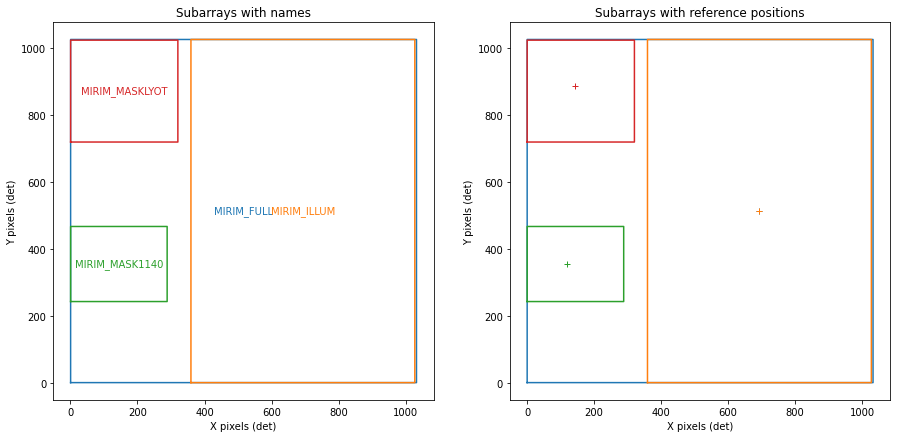

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 7.5))
# instr.plot(frame='det', ax=ax, names=['MIRIM_FULL','MIRIM_ILLUM','MIRIM_MASK1140','MIRIM_MASKLYOT'])
ax = axes[0]
ax.set_title("Subarrays with names")
for name, aper in apers.items():
    aper.plot(frame='det', ax=ax, fill=False, mark_ref=False, label=True)
ax = axes[1]
ax.set_title("Subarrays with reference positions")
for name, aper in apers.items():
    aper.plot(frame='det', ax=ax, fill=False, mark_ref=True, label=False)

In [7]:
print("In detector coordinates, the LYOT reference position is:", apers['MASKLYOT'].reference_point("det"))
print("In detector coordinates, the 1140 reference position is:", apers['MASK1140'].reference_point("det"))

In detector coordinates, the LYOT reference position is: (144.33, 885.88)
In detector coordinates, the 1140 reference position is: (120.75, 355.24)


### Find the Lyot reference position's coordinates in the 1140's IDL coordinate system.

The IDL coordinates for a subarray like MIRIM_MASK1140 are defined in arcsec (i.e., corrected for distortion), with (0, 0) defined at the subarray's reference position.

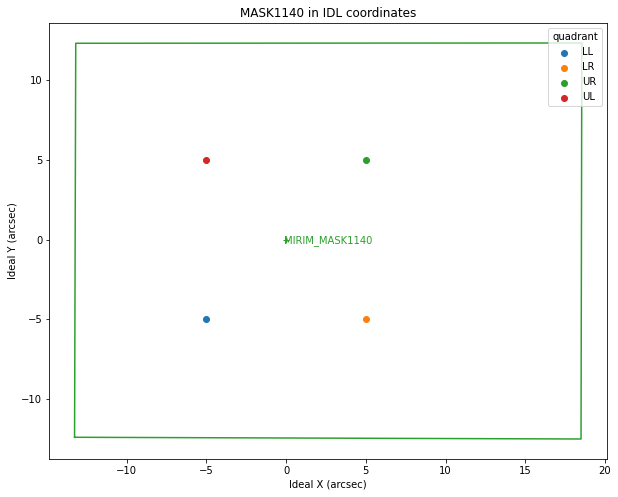

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))
apers['MASK1140'].plot(frame='idl', ax=ax, fill=False, mark_ref = True, label=True, c='C2')
ax.set_title("MASK1140 in IDL coordinates")
for q, i in {'LL': (-5, -5), 'LR': (5, -5), 'UR': (5, 5), 'UL': (-5, 5)}.items():
    ax.scatter(*i, marker='o', label=q)
ax.legend(loc='upper right', title='quadrant')

To find out what the Lyot's reference position is in IDL coordinates, we can use pysiaf's coordinate conversion tools. Both the MASK1140 and MASKLYOT apertures share the 'det' coordinate system, since that encompasses both subarrays.

In [9]:
lyot_ref = apers['MASKLYOT'].reference_point("det")
lyot_ref_in_1140_idl = apers['MASK1140'].det_to_idl(lyot_ref[0], lyot_ref[1])


The Lyot reference position is found at (x, y) = (2.8959, 58.7889) arcsec


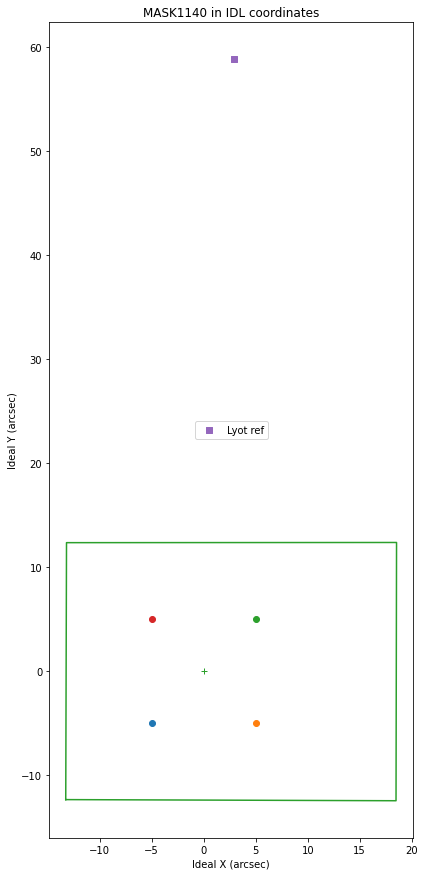

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 15))
apers['MASK1140'].plot(frame='idl', ax=ax, fill=False, mark_ref = True, c='C2')
ax.set_title("MASK1140 in IDL coordinates")
for q, i in {'LL': (-5, -5), 'LR': (5, -5), 'UR': (5, 5), 'UL': (-5, 5)}.items():
    ax.scatter(*i, marker='o')
ax.scatter(*lyot_ref_in_1140_idl, label='Lyot ref', marker='s')
ax.legend(loc='center')
print(f"The Lyot reference position is found at (x, y) = ({lyot_ref_in_1140_idl[0]:0.4f}, {lyot_ref_in_1140_idl[1]:0.4f}) arcsec")
print(f"The Lyot reference position is found at (x, y) = ({lyot_ref_in_1140_idl[0]:0.4f}, {lyot_ref_in_1140_idl[1]:0.4f}) arcsec")

## Convert arbitrary positions to 1140 IDL coordinates

Let's say we want to put a target on the bar at (x, y) = (-1, -10) in Lyot IDL coordinates. We can convert these to 1140 IDL coordinates through the detector coordinate system:

In [25]:
v3PA = 4.83544897   #V3 PA of the LYOT bar (based on the V3PA of F1140C coronagraph, which is the same for every coronagraphs)
dy = -7.5           #in arcsec, middle of the bar (15'')
dx = np.tan(v3PA*np.pi/180.)*dy  # in arcsec
print("dx = ",dx,'"')
print("dy = ",dy,'"')
star_coord_in_lyot_idl = (dx, dy)
star_det_coord = apers['MASKLYOT'].idl_to_det(*star_coord_in_lyot_idl)
star_coord_in_1140_idl = apers['MASK1140'].det_to_idl(*star_det_coord)

dx =  -0.6344658190965206 "
dy =  -7.5 "


The Lyot bar offset position is found at (x, y) = (2.2614, 51.2887) arcsec


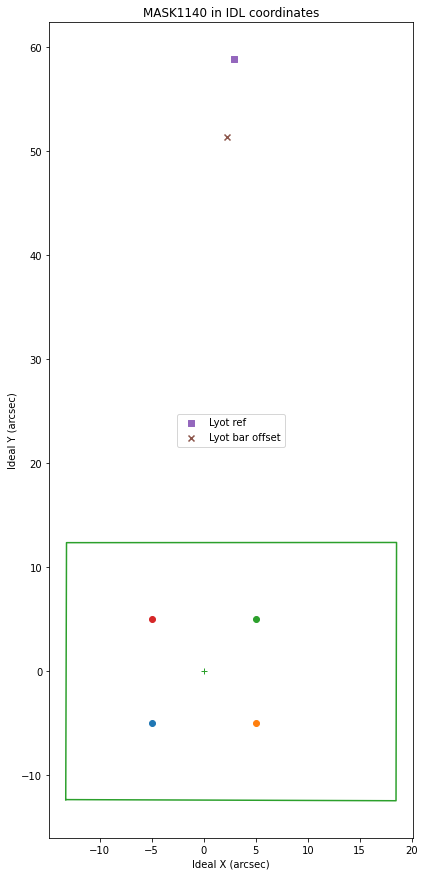

In [26]:
fig, ax = plt.subplots(figsize=(7.5, 15))
apers['MASK1140'].plot(frame='idl', ax=ax, fill=False, mark_ref = True, c='C2')
ax.set_title("MASK1140 in IDL coordinates")
for q, i in {'LL': (-5, -5), 'LR': (5, -5), 'UR': (5, 5), 'UL': (-5, 5)}.items():
    ax.scatter(*i, marker='o')
ax.scatter(*lyot_ref_in_1140_idl, label='Lyot ref', marker='s')
ax.scatter(*star_coord_in_1140_idl, label='Lyot bar offset', marker='x')
ax.legend(loc='center')
print(f"The Lyot bar offset position is found at (x, y) = ({star_coord_in_1140_idl[0]:0.4f}, {star_coord_in_1140_idl[1]:0.4f}) arcsec")

The Lyot bar offset position is found at (x, y) = (2.2614, 51.2887) arcsec. Since we want to put the star at this position, this is what we would enter into the Special Offsets field.